<center><h1>Huang_Shane_HW5</h1></center>
<br>
<br>

Name: Shane Huang
<br>
Github Username: shae513351
<br>
USC ID: 5886395143

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
%pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#import xgboost
from pathlib import Path
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, KFold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [3]:
DATA_DIR = Path("../data")

# Define column names following the order in diagnosis.names
# first six columns are predictors; the last two are targets
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "renal_pelvis_nephritis",
]

# Load the dataset
acute_df = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep="\t", # Attributes are separated by TAB
    header=None,
    names=columns, # Assign column names defined above
    encoding= "utf-16",
    decimal=",", # Interpret commas as decimal separators
)

# Preview the data and check its dimensions and missing values
display(acute_df.head())
print("Dataset shape:", acute_df.shape)
print("Missing values:", acute_df.isna().sum().sum())


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,renal_pelvis_nephritis
0,35.5,no,yes,no,no,no,no,no
1,35.9,no,no,yes,yes,yes,yes,no
2,35.9,no,yes,no,no,no,no,no
3,36.0,no,no,yes,yes,yes,yes,no
4,36.0,no,yes,no,no,no,no,no


Dataset shape: (120, 8)
Missing values: 0


### (b) Build a decision tree

In [4]:
# Copy the dataset to preserve the original yes/no values
acute_encoded = acute_df.copy()

# Encode all binary predictors and targets: no = 0, yes = 1
binary_columns = acute_encoded.columns[1:]
acute_encoded[binary_columns] = acute_encoded[binary_columns].apply(
    lambda col: col.map({"no": 0, "yes": 1})
)

# Use the first six columns as predictors
X_acute = acute_encoded.iloc[:, :6]

# Combine the two targets into four classes using label powerset
y_acute = (
    2 * acute_encoded["bladder_inflammation"]
    + acute_encoded["renal_pelvis_nephritis"]
)

# Define class names in the order of class labels 0, 1, 2, and 3
class_names = [
    "Neither disease",
    "Nephritis only",
    "Bladder inflammation only",
    "Both diseases",
]

# Fit an unpruned classification tree using the entire dataset
acute_tree = DecisionTreeClassifier(
    criterion="gini",
    random_state=42,
)
acute_tree.fit(X_acute, y_acute)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

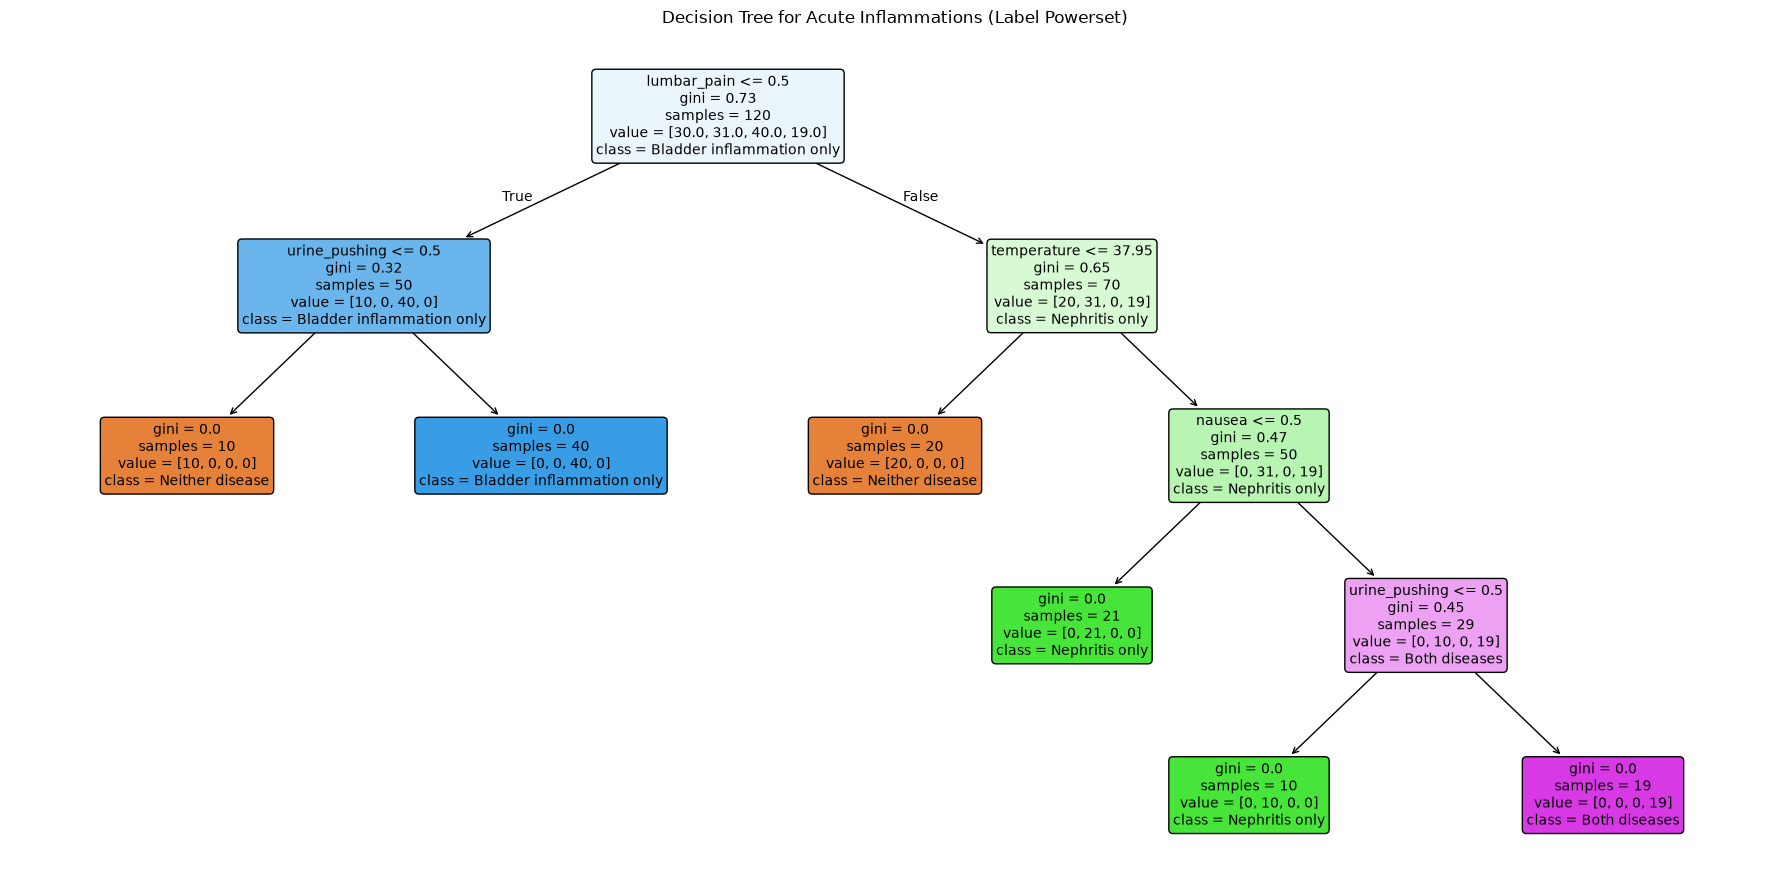

In [5]:
# Plot the fitted tree with predictor and class names
plt.figure(figsize=(18, 9))

plot_tree(
    acute_tree,
    feature_names=X_acute.columns.tolist(),
    class_names=class_names,
    filled=True,
    rounded=True,
    precision=2,
    fontsize=10,
)

plt.title("Decision Tree for Acute Inflammations (Label Powerset)")
plt.tight_layout()
plt.show()

### (c) Convert the decision rules

In [6]:
def generate_rules(model, feature_names, class_names):
    # Access the fitted tree structure
    tree = model.tree_
    rules = []

    def walk(node, conditions):
        # A leaf has no children: both child IDs are -1
        if tree.children_left[node] == tree.children_right[node]:
            # Select the class with the highest value at this leaf
            class_index = tree.value[node][0].argmax()
            prediction = class_names[class_index]

            # Combine all conditions along the current path
            condition_text = " AND ".join(conditions) if conditions else "TRUE"
            rules.append(
                f"IF {condition_text} THEN predict {prediction}."
            )
            return

        # Retrieve the predictor and threshold used at this split
        feature = feature_names[tree.feature[node]]
        threshold = tree.threshold[node]

        # Explore the left branch, where the split condition is true
        walk(
            tree.children_left[node],
            conditions + [f"{feature} <= {threshold:.2f}"],
        )

        # Explore the right branch, where the split condition is false
        walk(
            tree.children_right[node],
            conditions + [f"{feature} > {threshold:.2f}"],
        )

    # Start at the root node with an empty list of conditions
    walk(0, [])

    return rules


# Generate and display the rules for the fitted classification tree
rules = generate_rules(
    acute_tree,
    X_acute.columns.tolist(),
    class_names,
)

for i, rule in enumerate(rules, start=1):
    print(f"{i}. {rule}")

1. IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN predict Neither disease.
2. IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN predict Bladder inflammation only.
3. IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN predict Neither disease.
4. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN predict Nephritis only.
5. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN predict Nephritis only.
6. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN predict Both diseases.


### (d) Cost-complexity pruning

In [7]:
# Obtain candidate alpha values from the cost-complexity pruning path
pruning_path = acute_tree.cost_complexity_pruning_path(X_acute, y_acute)
ccp_alphas = np.unique(pruning_path.ccp_alphas)

# Preserve approximately the same class proportions across five folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

pruning_results = []

# Evaluate each candidate alpha using the same cross-validation folds
for alpha in ccp_alphas:
    model = DecisionTreeClassifier(
        criterion="gini",
        ccp_alpha=alpha,
        random_state=42,
    )

    cv_scores = cross_val_score(
        model,
        X_acute,
        y_acute,
        cv=cv,
        scoring="accuracy",
    )

    # Fit on all observations to measure the resulting tree's size
    model.fit(X_acute, y_acute)

    pruning_results.append({
        "Alpha": alpha,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Training Accuracy": model.score(X_acute, y_acute),
        "CV Accuracy": cv_scores.mean(),
    })

# Compare predictive performance and tree complexity
pruning_df = pd.DataFrame(pruning_results)
display(pruning_df)

,Alpha,Depth,Leaves,Training Accuracy,CV Accuracy
0,0.000000,4,6,1.000000,0.991667
1,0.098167,2,4,0.841667,0.858333
2,0.133333,2,3,0.758333,0.758333
3,0.182000,1,2,0.591667,0.666667
4,0.222917,0,1,0.333333,0.483333


In [8]:
# Select the highest CV accuracy; prefer fewer leaves if scores are tied
best_row = pruning_df.sort_values(
    by=["CV Accuracy", "Leaves"],
    ascending=[False, True],
).iloc[0]

best_alpha = float(best_row["Alpha"])

# Fit the selected model on the entire dataset
selected_tree = DecisionTreeClassifier(
    criterion="gini",
    ccp_alpha=best_alpha,
    random_state=42,
)
selected_tree.fit(X_acute, y_acute)

print(f"Selected alpha: {best_alpha:.6f}")

# Generate the decision rules for the selected model
selected_rules = generate_rules(
    selected_tree,
    X_acute.columns.tolist(),
    class_names,
)

for i, rule in enumerate(selected_rules, start=1):
    print(f"{i}. {rule}")

Selected alpha: 0.000000
1. IF lumbar_pain <= 0.50 AND urine_pushing <= 0.50 THEN predict Neither disease.
2. IF lumbar_pain <= 0.50 AND urine_pushing > 0.50 THEN predict Bladder inflammation only.
3. IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN predict Neither disease.
4. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea <= 0.50 THEN predict Nephritis only.
5. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing <= 0.50 THEN predict Nephritis only.
6. IF lumbar_pain > 0.50 AND temperature > 37.95 AND nausea > 0.50 AND urine_pushing > 0.50 THEN predict Both diseases.


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [9]:
# Extract column names from the attribute definitions
with open(DATA_DIR / "communities.names", encoding="utf-8") as file:
    crime_columns = [
        line.split()[1]
        for line in file
        if line.startswith("@attribute")
    ]

# Load the comma-separated data and recognize "?" as missing values
crime_df = pd.read_csv(
    DATA_DIR / "communities.data",
    sep=",",
    header=None,
    names=crime_columns,
    na_values="?",
)

# Preview the dataset
display(crime_df.head())
print("Dataset shape:", crime_df.shape)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


Dataset shape: (1994, 128)


In [10]:
# Preserve the original row order when splitting the dataset
crime_train = crime_df.iloc[:1495].copy()
crime_test = crime_df.iloc[1495:].copy()

print("Training set shape:", crime_train.shape)
print("Test set shape:", crime_test.shape)

Training set shape: (1495, 128)
Test set shape: (499, 128)


### (b) Missing values

In [11]:
# Identify nonpredictive attributes and the regression target
nonpredictive_columns = [
    "state",
    "county",
    "community",
    "communityname",
    "fold",
]
target = "ViolentCrimesPerPop"

# Separate predictors from the target in each dataset
X_train = crime_train.drop(columns=nonpredictive_columns + [target])
X_test = crime_test.drop(columns=nonpredictive_columns + [target])

y_train = crime_train[target]
y_test = crime_test[target]

In [12]:
# Estimate each predictor's median from the training set
imputer = SimpleImputer(strategy="median")

# Impute training data and preserve column names and row indices
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index,
)

# Impute test data using the medians learned from the training set
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index,
)

# Check dimensions and confirm that no missing values remain
print("Training predictors:", X_train_imputed.shape)
print("Test predictors:", X_test_imputed.shape)
print("Training missing values:", X_train_imputed.isna().sum().sum())
print("Test missing values:", X_test_imputed.isna().sum().sum())

Training predictors: (1495, 122)
Test predictors: (499, 122)
Training missing values: 0
Test missing values: 0


### (c) Plot a correlation matrix

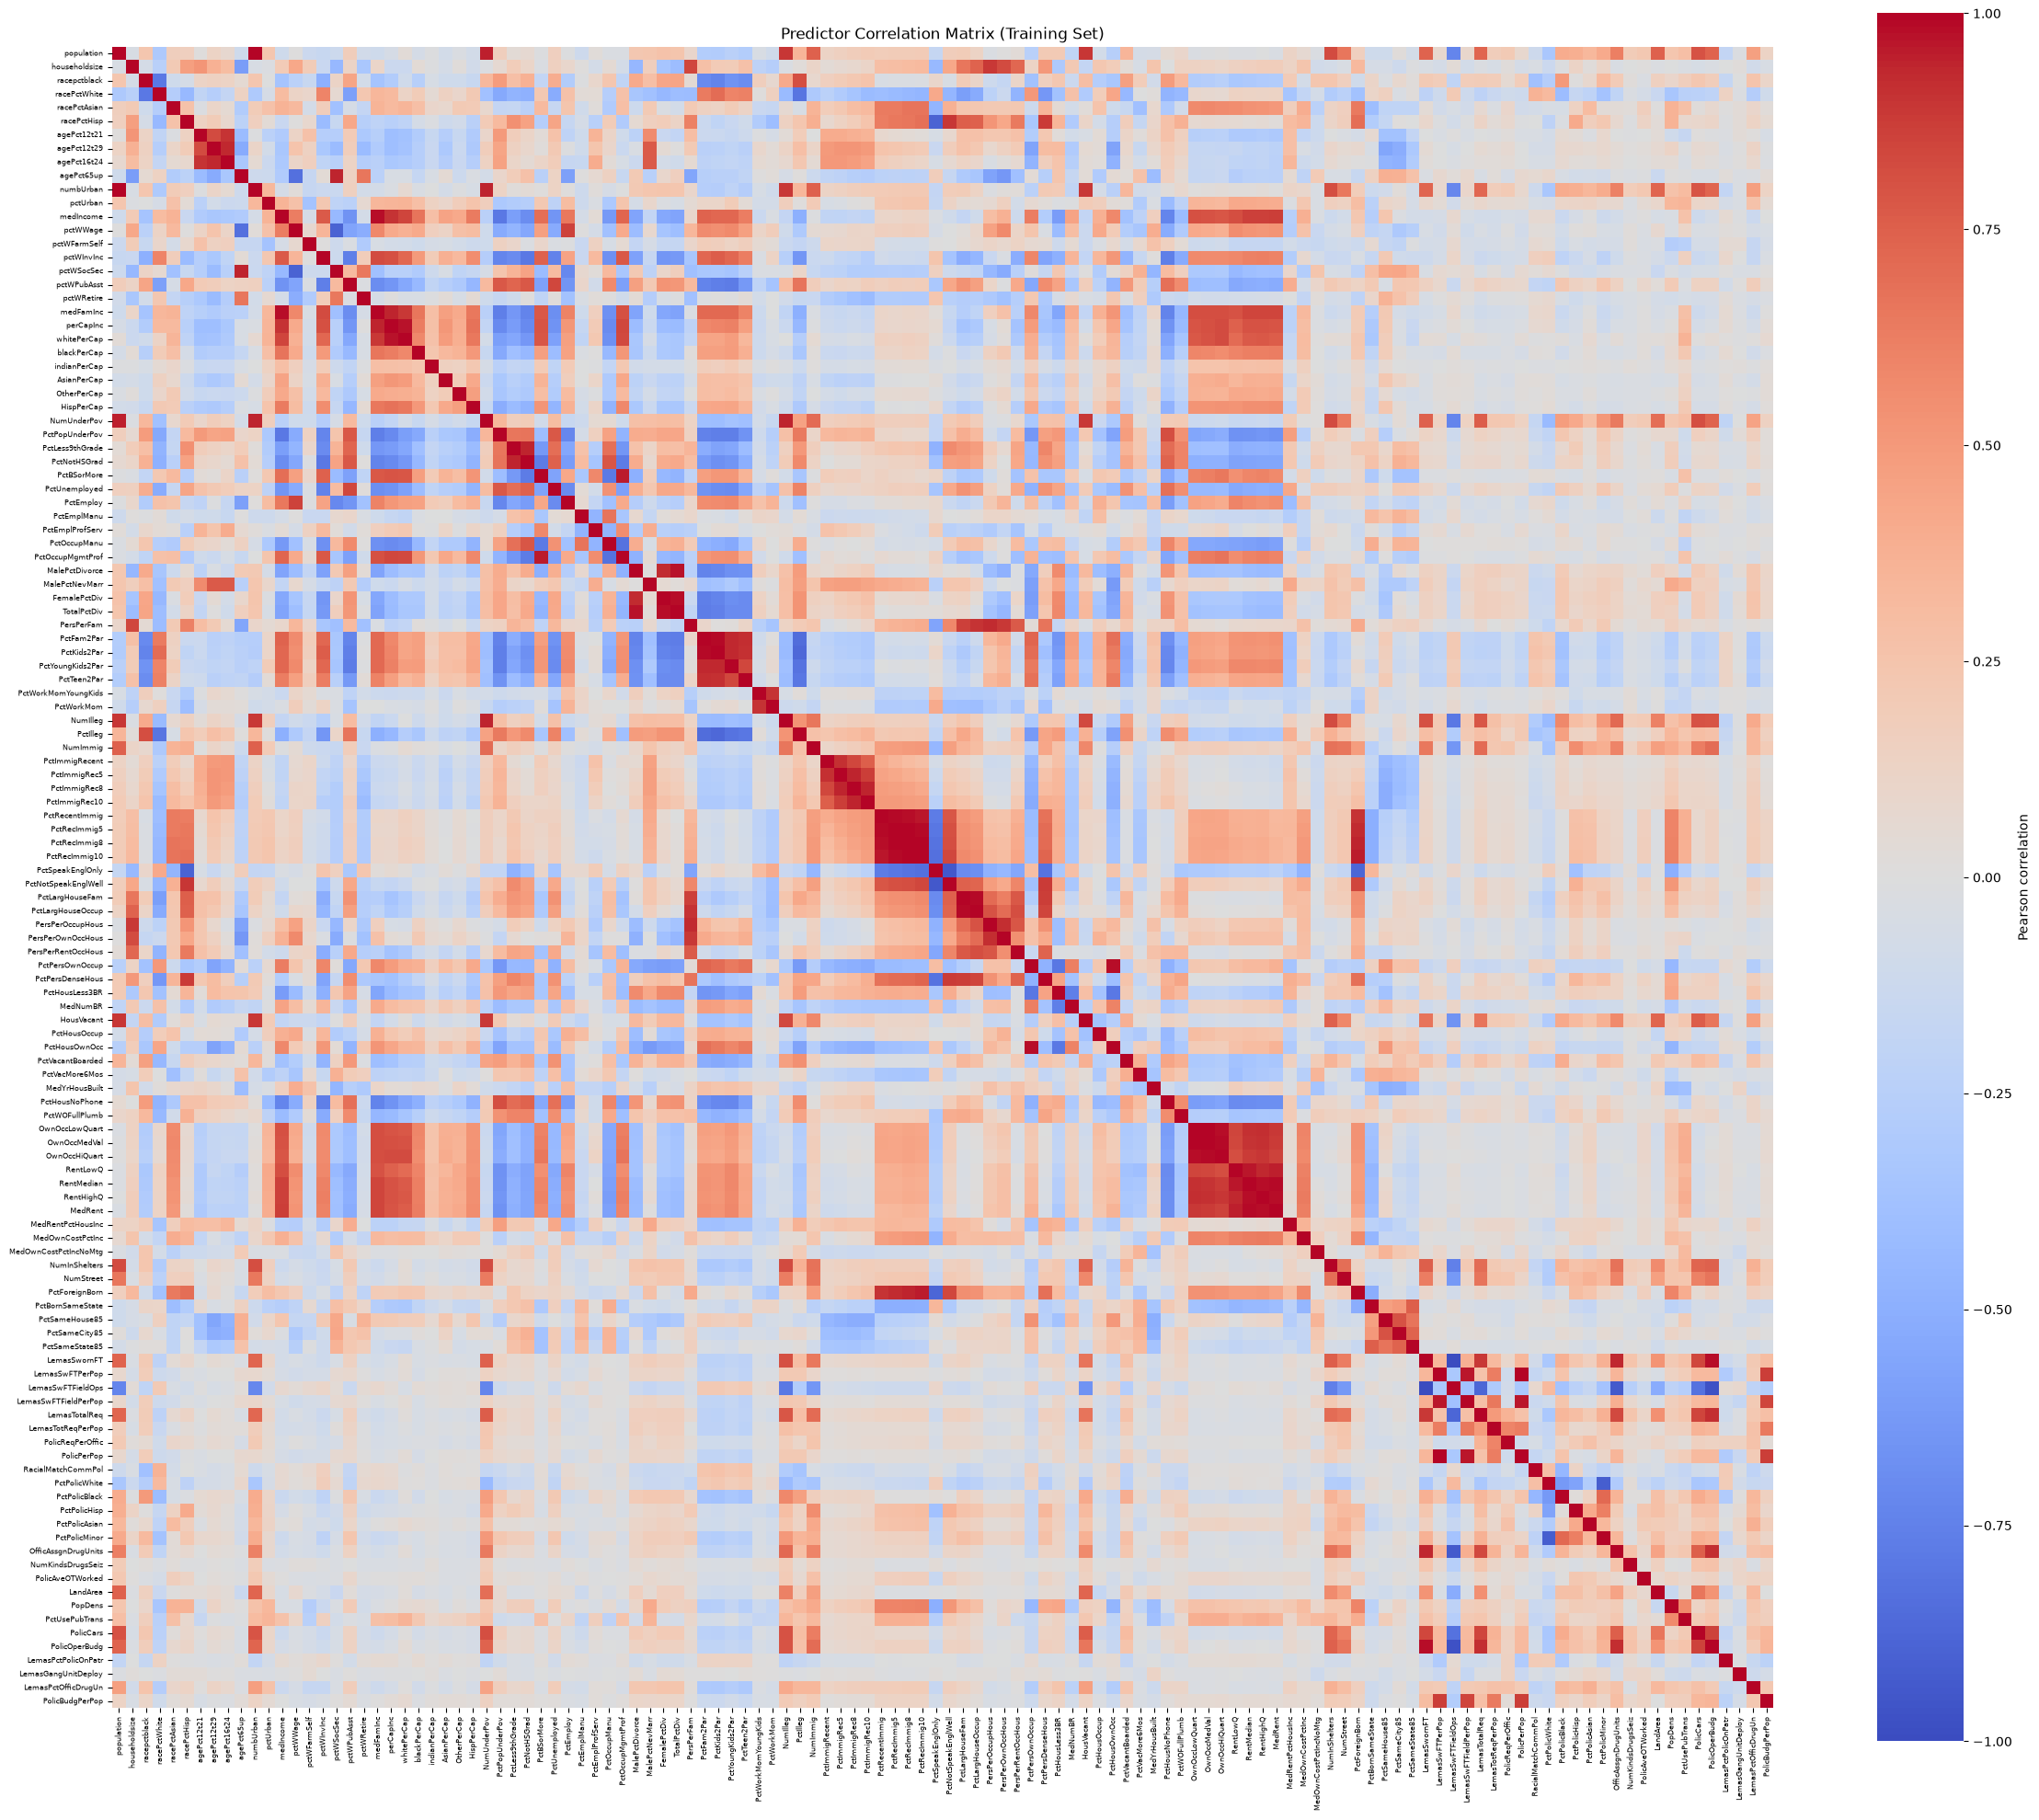

In [13]:
# Calculate pairwise Pearson correlations using the imputed training data
correlation_matrix = X_train_imputed.corr(method="pearson")

# Plot all 122 predictors in a correlation heatmap
plt.figure(figsize=(24, 20))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",       # Blue indicates negative; red indicates positive
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    annot=False,          # Avoid overcrowding the plot with numeric values
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Pearson correlation"},
)

# Adjust labels to accommodate the large number of predictors
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)

plt.title("Predictor Correlation Matrix (Training Set)")
plt.tight_layout()
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [14]:
# Calculate the mean and sample standard deviation of each predictor
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

# Calculate the coefficient of variation for all 122 predictors
cv_summary = pd.DataFrame({
    "Mean": feature_means,
    "Sample Std": feature_stds,
    "CV": feature_stds / feature_means,
}).rename_axis("Feature")

# Rank predictors from highest to lowest coefficient of variation
cv_summary = cv_summary.sort_values(by="CV", ascending=False)

display(cv_summary)

,Mean,Sample Std,CV
Feature,,,
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
...,...,...,...
NumKindsDrugsSeiz,0.567130,0.079977,0.141021
RacialMatchCommPol,0.722375,0.093657,0.129652
PctPolicWhite,0.762856,0.090572,0.118727


### (e) Scatter plots and box plots for highest CV features

In [15]:
# Select the 11 predictors with the highest coefficients of variation
n_features = int(np.sqrt(128))
high_cv_features = cv_summary.head(n_features).index.tolist()

# Display the selected predictors and their CV values
display(cv_summary.loc[high_cv_features, ["CV"]])

,CV
Feature,
PctPolicAsian,5.527059
NumStreet,4.292923
NumInShelters,3.470952
NumIlleg,3.058964
NumImmig,2.926635
LemasPctOfficDrugUn,2.552946
NumUnderPov,2.342443
LemasSwornFT,2.248042
population,2.241105


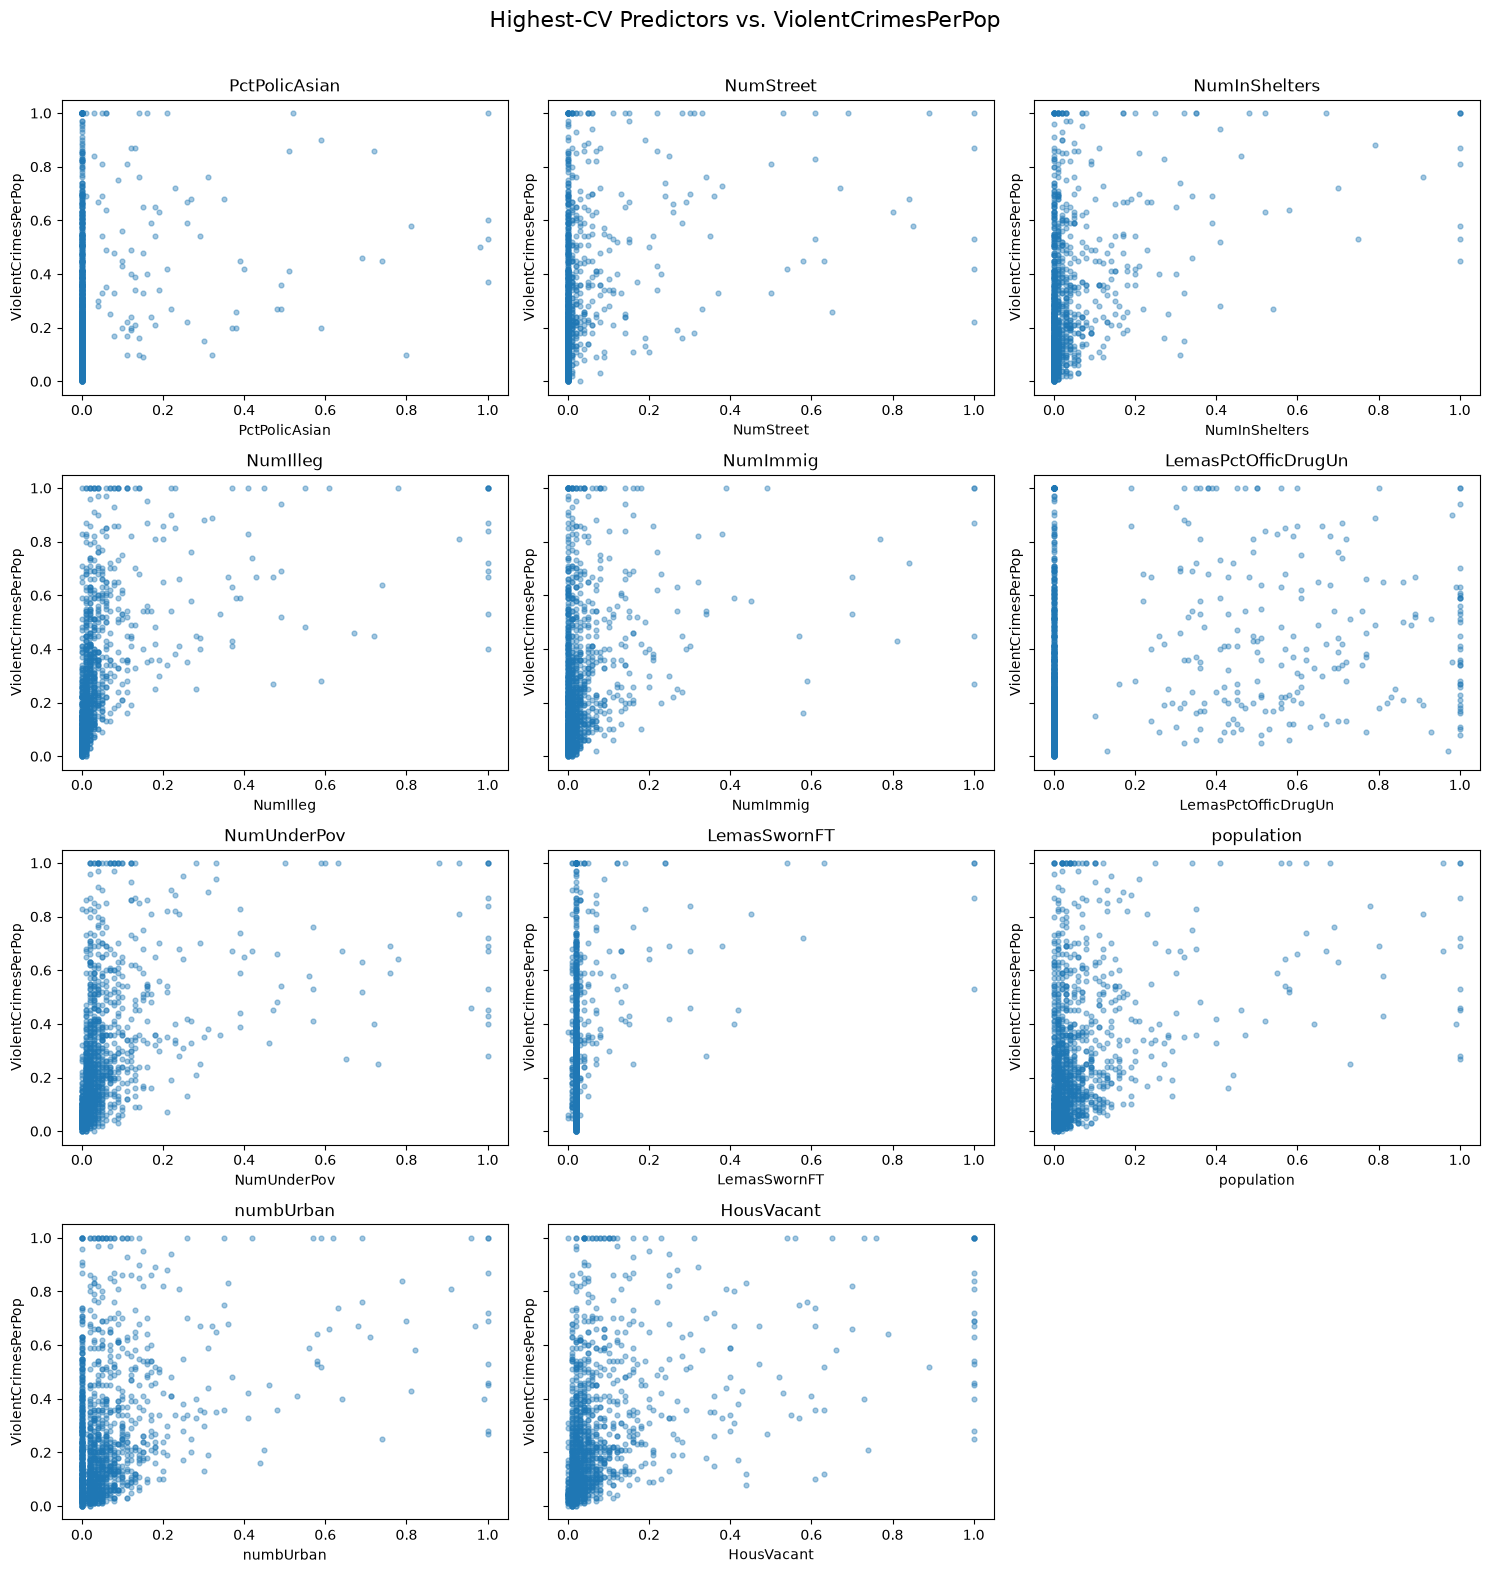

In [16]:
# Create a grid for the 11 predictor-versus-target scatter plots
fig, axes = plt.subplots(
    4, 3,
    figsize=(15, 16),
    sharey=True,
)

# Plot each selected predictor against the regression target
for ax, feature in zip(axes.flat, high_cv_features):
    ax.scatter(
        X_train_imputed[feature],
        y_train,
        s=12,
        alpha=0.4,
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")

# Hide the unused twelfth subplot
axes.flat[-1].axis("off")

fig.suptitle(
    "Highest-CV Predictors vs. ViolentCrimesPerPop",
    fontsize=16,
)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

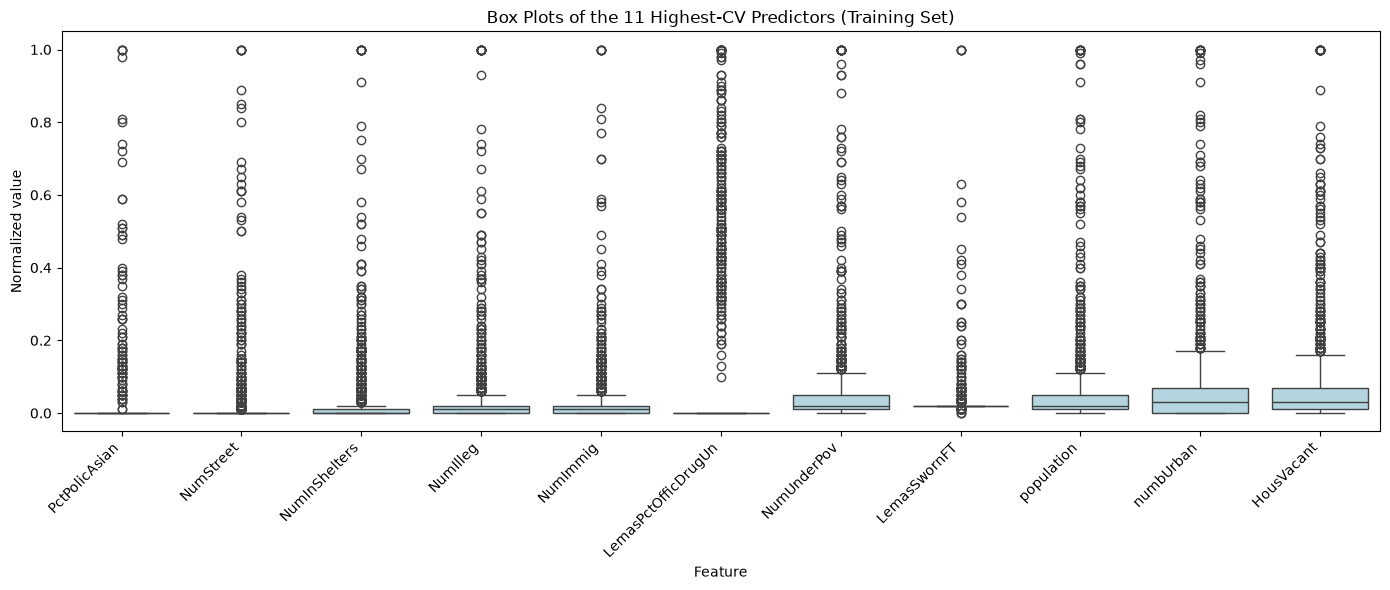

In [17]:
# Compare the distributions of the 11 selected predictors
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=X_train_imputed[high_cv_features],
    color="lightblue",
)

plt.xticks(rotation=45, ha="right")
plt.xlabel("Feature")
plt.ylabel("Normalized value")
plt.title("Box Plots of the 11 Highest-CV Predictors (Training Set)")
plt.tight_layout()
plt.show()

Statistical significance can not be determined from scatter plots alone; formal inference under appropriate model assumptions is needed. Also, a high coefficient of variation does not necessarily imply predictive importance or statistical significance.

### (f) Fit a linear model

In [18]:
# Fit an ordinary least-squares model using all 122 imputed predictors
linear_model = LinearRegression()
linear_model.fit(X_train_imputed, y_train)

# Predict the target values for the test set
y_pred_linear = linear_model.predict(X_test_imputed)

# Calculate the mean squared prediction error on the test set
linear_test_mse = mean_squared_error(y_test, y_pred_linear)

print(f"Linear Regression Test MSE: {linear_test_mse:.6f}")

Linear Regression Test MSE: 0.017966


### (g) Fit a ridge regression model

In [19]:
# Apply imputation, standardization, and Ridge within each CV fold
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", Ridge()),
])

# Use the same five folds for all candidate alpha values
regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Search 81 alpha values from 0.0001 to 10000 on a logarithmic scale
ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": np.logspace(-4, 4, 81)},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

# Select alpha by CV and refit the best pipeline on all training data
ridge_search.fit(X_train, y_train)

# Predict using preprocessing learned from the training data
y_pred_ridge = ridge_search.predict(X_test)
ridge_test_mse = mean_squared_error(y_test, y_pred_ridge)

print(f"Selected lambda (alpha): {ridge_search.best_params_['ridge__alpha']:.6f}")
print(f"Best CV MSE: {-ridge_search.best_score_:.6f}")
print(f"Ridge Test MSE: {ridge_test_mse:.6f}")

Selected lambda (alpha): 125.892541
Best CV MSE: 0.019738
Ridge Test MSE: 0.017372


### (h) Fit a LASSO model

In [20]:
# Define LASSO pipelines with and without standardization
lasso_pipelines = {
    "Without standardization": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("lasso", Lasso(max_iter=100000)),
    ]),
    "With standardization": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("lasso", Lasso(max_iter=100000)),
    ]),
}

In [21]:
lasso_results = []

# Tune and evaluate each preprocessing configuration
for name, pipeline in lasso_pipelines.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"lasso__alpha": np.logspace(-5, -1, 41)},
        scoring="neg_mean_squared_error",
        cv=regression_cv,
    )
    search.fit(X_train, y_train)

    # Evaluate the best pipeline on the test set
    predictions = search.predict(X_test)
    test_mse = mean_squared_error(y_test, predictions)

    # Identify predictors with nonzero coefficients
    coefficients = search.best_estimator_.named_steps["lasso"].coef_
    selected_features = X_train.columns[coefficients != 0].tolist()

    # Store performance and the selected predictor names
    lasso_results.append({
        "Model": name,
        "Alpha": search.best_params_["lasso__alpha"],
        "CV MSE": -search.best_score_,
        "Test MSE": test_mse,
        "Selected Count": len(selected_features),
        "Selected Features": selected_features,
    })

# Display performance separately from the feature lists
lasso_summary = pd.DataFrame(lasso_results)
display(lasso_summary.drop(columns="Selected Features"))

for result in lasso_results:
    print(f"\n{result['Model']} — selected features:")
    print(", ".join(result["Selected Features"]))

,Model,Alpha,CV MSE,Test MSE,Selected Count
0,Without standardization,0.000126,0.019521,0.017616,74
1,With standardization,0.000631,0.019661,0.017723,76



Without standardization — selected features:
racepctblack, racePctAsian, agePct12t21, agePct12t29, pctUrban, pctWWage, pctWFarmSelf, pctWInvInc, pctWSocSec, pctWPubAsst, pctWRetire, whitePerCap, blackPerCap, indianPerCap, AsianPerCap, OtherPerCap, HispPerCap, PctPopUnderPov, PctLess9thGrade, PctEmploy, PctEmplManu, PctOccupManu, MalePctDivorce, MalePctNevMarr, FemalePctDiv, PctKids2Par, PctYoungKids2Par, PctTeen2Par, PctWorkMom, NumIlleg, PctIlleg, NumImmig, PctImmigRecent, PctImmigRec10, PctRecImmig10, PctNotSpeakEnglWell, PctLargHouseOccup, PersPerOccupHous, PctPersOwnOccup, PctPersDenseHous, PctHousLess3BR, MedNumBR, HousVacant, PctHousOccup, PctVacantBoarded, PctVacMore6Mos, MedYrHousBuilt, PctHousNoPhone, PctWOFullPlumb, OwnOccLowQuart, RentLowQ, MedRent, MedRentPctHousInc, MedOwnCostPctInc, MedOwnCostPctIncNoMtg, NumInShelters, NumStreet, PctForeignBorn, PctBornSameState, PctSameCity85, LemasSwFTFieldPerPop, PolicReqPerOffic, RacialMatchCommPol, PctPolicBlack, PctPolicHisp, PctP

The unstandardized model had a slightly lower test MSE and retained
fewer predictors.

### (i) Fit a PCR model

In [22]:
# Combine preprocessing, PCA, and least-squares regression
pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression()),
])

# Select the number of principal components using five-fold CV
pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={
        "pca__n_components": list(range(1, X_train.shape[1] + 1))
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

# Refit the best pipeline on the entire training set
pcr_search.fit(X_train, y_train)

# Evaluate the selected PCR model on the test set
y_pred_pcr = pcr_search.predict(X_test)
pcr_test_mse = mean_squared_error(y_test, y_pred_pcr)

print(f"Selected M: {pcr_search.best_params_['pca__n_components']}")
print(f"Best CV MSE: {-pcr_search.best_score_:.6f}")
print(f"PCR Test MSE: {pcr_test_mse:.6f}")

Selected M: 60
Best CV MSE: 0.020210
PCR Test MSE: 0.018350


### (j) Fit a boosting tree

In [23]:
# Combine median imputation and L1-regularized tree boosting
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        reg_lambda=0.0,
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )),
])

# Select the L1 penalty using the same five-fold CV splits
xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={
        "xgb__reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10, 100]
    },
    scoring="neg_mean_squared_error",
    cv=regression_cv,
)

# Refit the best pipeline on all training observations
xgb_search.fit(X_train, y_train)

# Evaluate the selected model on the test set
y_pred_xgb = xgb_search.predict(X_test)
xgb_test_mse = mean_squared_error(y_test, y_pred_xgb)

print(f"Selected alpha: {xgb_search.best_params_['xgb__reg_alpha']}")
print(f"Best CV MSE: {-xgb_search.best_score_:.6f}")
print(f"XGBoost Test MSE: {xgb_test_mse:.6f}")

Selected alpha: 1
Best CV MSE: 0.020075
XGBoost Test MSE: 0.016703
